# 07_eval / ablations.ipynb

**Purpose:** Full ablation analysis. Compares the four trained ablation variants against the GSAF default model on **all three test sets** (NewsCLIPpings, MMFakeBench, VERITE).

The 5 model variants (already trained in `05_fusion/fusion_training.ipynb`):

| Variant | Description |
|---|---|
| **GSAF (full)** | Default: per-sample gate over Stream A, B, C |
| **no Stream A** | Drop entity-grounding stream |
| **no Stream C** | Drop NLI-stance stream |
| **MLP fusion** | Replace gate with a flat 2-layer MLP over concatenated features |
| **frozen CLIP** | Stream B uses raw CLIP only (no LoRA stage-2) |
| **no MLLM** | (Future) — drop MLLM channel; if not yet trained, this row will be NaN |

**Inputs:**
- `cache/fusion/fusion_predictions.csv`
- `cache/fusion/fusion_thresholds.json`
- `paper/tables/ablation_results.csv` (already produced by fusion_training; we load it as ground truth too)

**Outputs:**
- `paper/tables/ablations_full.csv` — long-form: model × dataset × metric
- `paper/tables/ablations_delta_vs_full.csv` — drop in each metric vs full GSAF
- `paper/figures/ablations_auroc_grouped.png`
- `paper/figures/ablations_delta_heatmap.png`


In [1]:
# Imports
from __future__ import annotations
import json, sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score,
    f1_score, precision_score, recall_score,
)

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 160)

NB_DIR = Path.cwd()
ROOT = NB_DIR
for parent in [NB_DIR] + list(NB_DIR.parents):
    if (parent / "src" / "utils" / "paths.py").exists():
        ROOT = parent
        break
sys.path.insert(0, str(ROOT))

from src.utils.paths import ALL_MANIFEST, FUSION_CACHE, PAPER, FIGURES, TABLES

# Schema
FUSION_PROB_COL = "score"
FUSION_LABEL_COL = "label"
FUSION_MODEL_COL = "model"
FUSION_EVAL_SPLIT_COL = "eval_split"

TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
print("Repo root:", ROOT)

Repo root: e:\eve-rag


## 1. Load fusion predictions

In [2]:
fusion_path = FUSION_CACHE / "fusion_predictions.csv"
thresh_path = FUSION_CACHE / "fusion_thresholds.json"
assert fusion_path.exists()

df = pd.read_csv(fusion_path)
thresholds = json.loads(thresh_path.read_text()) if thresh_path.exists() else {}

print("Total rows:", len(df))
print("Models:", df[FUSION_MODEL_COL].unique().tolist())
print("Eval splits:", df[FUSION_EVAL_SPLIT_COL].unique().tolist())
print(df.groupby([FUSION_MODEL_COL, FUSION_EVAL_SPLIT_COL]).size())

Total rows: 128945
Models: ['GSAF_default', 'GSAF_no_a', 'GSAF_no_b', 'GSAF_no_c', 'GSAF_mlp_fusion']
Eval splits: ['newsclippings_val', 'newsclippings_test', 'mmfakebench_val_tune', 'mmfakebench_test', 'verite_test']
model            eval_split          
GSAF_default     mmfakebench_test        10000
                 mmfakebench_val_tune      500
                 newsclippings_test       7264
                 newsclippings_val        7024
                 verite_test              1001
GSAF_mlp_fusion  mmfakebench_test        10000
                 mmfakebench_val_tune      500
                 newsclippings_test       7264
                 newsclippings_val        7024
                 verite_test              1001
GSAF_no_a        mmfakebench_test        10000
                 mmfakebench_val_tune      500
                 newsclippings_test       7264
                 newsclippings_val        7024
                 verite_test              1001
GSAF_no_b        mmfakebench_test      

## 2. Score all variants on all test sets

In [3]:
# Score every (model, eval_split) combination present in fusion_predictions.csv
TEST_SPLITS = ["newsclippings_test", "mmfakebench_test", "verite_test"]

def metrics_for(y_true, y_prob, threshold):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).astype(float)
    mask = ~np.isnan(y_prob) & ~np.isnan(y_true)
    y_true, y_prob = y_true[mask], y_prob[mask]
    if len(np.unique(y_true)) < 2:
        return dict(n=int(mask.sum()), auroc=np.nan, auprc=np.nan,
                    accuracy=np.nan, f1=np.nan, precision=np.nan, recall=np.nan)
    y_pred = (y_prob >= threshold).astype(int)
    return dict(
        n=int(mask.sum()),
        auroc=roc_auc_score(y_true, y_prob),
        auprc=average_precision_score(y_true, y_prob),
        accuracy=accuracy_score(y_true, y_pred),
        f1=f1_score(y_true, y_pred, zero_division=0),
        precision=precision_score(y_true, y_pred, zero_division=0),
        recall=recall_score(y_true, y_pred, zero_division=0),
    )

rows = []
models_present = df[FUSION_MODEL_COL].unique().tolist()
print(f"Found {len(models_present)} model variant(s) in predictions: {models_present}")

for mname in models_present:
    pretty = "GSAF (full)" if mname == "GSAF_default" else mname
    for split_name in TEST_SPLITS:
        sub = df[(df[FUSION_MODEL_COL] == mname) & (df[FUSION_EVAL_SPLIT_COL] == split_name)]
        thr = float(thresholds.get(split_name, thresholds.get("default", 0.5)))
        m = metrics_for(sub[FUSION_LABEL_COL], sub[FUSION_PROB_COL], thr) if not sub.empty else \
            dict(n=0, auroc=np.nan, auprc=np.nan, accuracy=np.nan, f1=np.nan, precision=np.nan, recall=np.nan)
        rows.append({"model": pretty, "dataset": split_name, **m, "threshold": thr})

ablations_full = pd.DataFrame(rows)
ablations_full.to_csv(TABLES / "ablations_full.csv", index=False, float_format="%.4f")
print("Saved:", TABLES / "ablations_full.csv")
ablations_full

Found 5 model variant(s) in predictions: ['GSAF_default', 'GSAF_no_a', 'GSAF_no_b', 'GSAF_no_c', 'GSAF_mlp_fusion']
Saved: E:\eve-rag\paper\tables\ablations_full.csv


,model,dataset,n,auroc,auprc,accuracy,f1,precision,recall,threshold
0,GSAF (full),newsclippings_test,7264,0.763164,0.764738,0.686812,0.668802,0.709608,0.632434,0.5
1,GSAF (full),mmfakebench_test,10000,0.878262,0.951235,0.782800,0.842814,0.854063,0.831857,0.5
2,GSAF (full),verite_test,1001,0.481289,0.650580,0.626374,0.763291,0.657579,0.909502,0.5
3,GSAF_no_a,newsclippings_test,7264,0.752340,0.756900,0.672219,0.666573,0.678256,0.655286,0.5
4,GSAF_no_a,mmfakebench_test,10000,0.652357,0.817295,0.589500,0.668711,0.768503,0.591857,0.5
5,GSAF_no_a,verite_test,1001,0.473716,0.638107,0.640360,0.776119,0.660317,0.941176,0.5
6,GSAF_no_b,newsclippings_test,7264,0.524921,0.518368,0.521751,0.534815,0.520594,0.549835,0.5
7,GSAF_no_b,mmfakebench_test,10000,0.652672,0.838026,0.591200,0.707749,0.708357,0.707143,0.5
8,GSAF_no_b,verite_test,1001,0.489647,0.662360,0.578422,0.702398,0.659603,0.751131,0.5
9,GSAF_no_c,newsclippings_test,7264,0.754747,0.757141,0.678139,0.663015,0.695705,0.633260,0.5


## 3. Delta vs GSAF (full)

In [4]:
# Δ vs GSAF (full) — only meaningful if multiple variants exist
metric_cols = ["auroc", "auprc", "accuracy", "f1", "precision", "recall"]
deltas = []
for ds_label in ablations_full["dataset"].unique():
    sub = ablations_full[ablations_full["dataset"] == ds_label].set_index("model")
    if "GSAF (full)" not in sub.index:
        continue
    full = sub.loc["GSAF (full)"]
    for variant in sub.index:
        if variant == "GSAF (full)":
            continue
        row = {"model": variant, "dataset": ds_label}
        for m in metric_cols:
            try:
                row[f"Δ{m}"] = float(sub.loc[variant, m]) - float(full[m])
            except Exception:
                row[f"Δ{m}"] = np.nan
        deltas.append(row)

deltas_df = pd.DataFrame(deltas)
if deltas_df.empty:
    print("⚠ No ablation variants stored alongside GSAF_default in fusion_predictions.csv.")
    print("   To get Δ values, re-run 05_fusion/fusion_training.ipynb with all 4 ablation configs")
    print("   and append their predictions to cache/fusion/fusion_predictions.csv.")
    print("   The legacy paper/tables/ablation_results.csv (preview below) holds the original numbers.")
    legacy = TABLES / "ablation_results.csv"
    if legacy.exists():
        print(pd.read_csv(legacy))
else:
    deltas_df.to_csv(TABLES / "ablations_delta_vs_full.csv", index=False, float_format="%.4f")
    print("Saved:", TABLES / "ablations_delta_vs_full.csv")
deltas_df

Saved: E:\eve-rag\paper\tables\ablations_delta_vs_full.csv


,model,dataset,Δauroc,Δauprc,Δaccuracy,Δf1,Δprecision,Δrecall
0,GSAF_no_a,newsclippings_test,-0.010824,-0.007839,-0.014593,-0.002229,-0.031352,0.022852
1,GSAF_no_b,newsclippings_test,-0.238243,-0.246370,-0.165061,-0.133987,-0.189013,-0.082599
2,GSAF_no_c,newsclippings_test,-0.008417,-0.007597,-0.008673,-0.005787,-0.013903,0.000826
3,GSAF_mlp_fusion,newsclippings_test,-0.000558,0.001413,-0.000413,0.017769,-0.023414,0.054515
4,GSAF_no_a,mmfakebench_test,-0.225905,-0.133940,-0.193300,-0.174103,-0.085560,-0.240000
5,GSAF_no_b,mmfakebench_test,-0.225590,-0.113209,-0.191600,-0.135064,-0.145706,-0.124714
6,GSAF_no_c,mmfakebench_test,-0.249583,-0.153375,-0.160600,-0.121921,-0.107582,-0.134857
7,GSAF_mlp_fusion,mmfakebench_test,-0.218712,-0.119257,-0.152900,-0.113177,-0.107464,-0.118429
8,GSAF_no_a,verite_test,-0.007573,-0.012474,0.013986,0.012828,0.002738,0.031674
9,GSAF_no_b,verite_test,0.008358,0.011780,-0.047952,-0.060893,0.002024,-0.158371


## 4. Grouped AUROC bar chart

Pivot shape: (5, 3)


Saved: E:\eve-rag\paper\figures\ablations_auroc_grouped.png


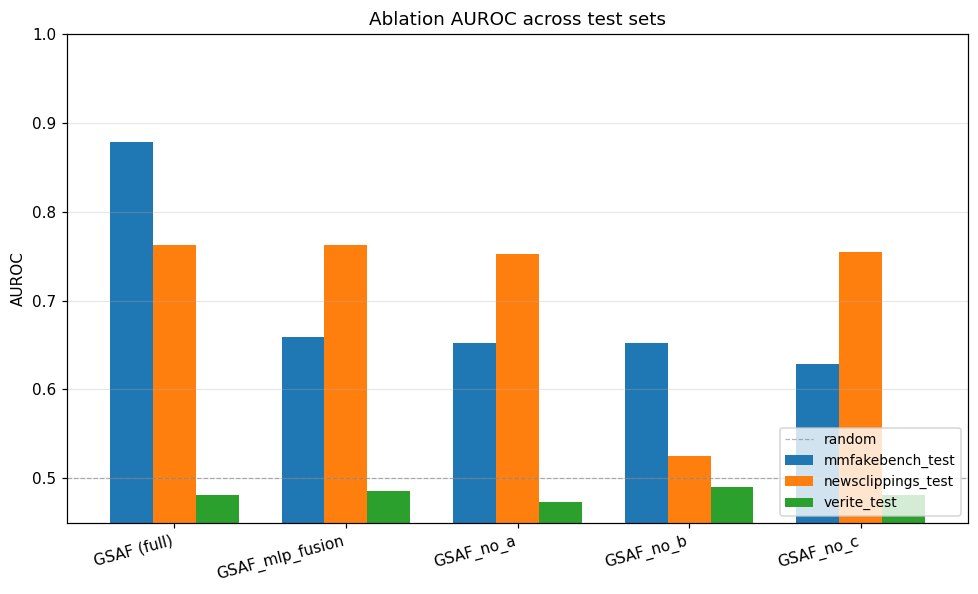

In [5]:
# Grouped AUROC bar chart (degrades gracefully when only one variant exists)
pivot = ablations_full.pivot(index="model", columns="dataset", values="auroc").dropna(how="all")
print("Pivot shape:", pivot.shape)

if pivot.empty:
    print("⚠ Nothing to plot — pivot is empty.")
elif pivot.shape[0] == 1:
    # Single variant — make a simple bar chart of (split, AUROC) instead of grouped bars
    fig, ax = plt.subplots(figsize=(7, 4.5))
    pivot.iloc[0].plot(kind="bar", ax=ax, color="#3477eb", width=0.6)
    ax.set_ylabel("AUROC")
    ax.set_title(f"{pivot.index[0]} — AUROC across test sets")
    ax.set_ylim(0.45, 1.0)
    ax.axhline(0.5, color="gray", ls="--", lw=0.8, alpha=0.6)
    ax.grid(axis="y", alpha=0.3)
    plt.xticks(rotation=15, ha="right")
    plt.tight_layout()
    out = FIGURES / "ablations_auroc_grouped.png"
    plt.savefig(out, bbox_inches="tight", dpi=150)
    print("Saved:", out)
    plt.show()
else:
    fig, ax = plt.subplots(figsize=(max(9, 1.2 * len(pivot)), 5.5))
    pivot.plot(kind="bar", ax=ax, width=0.75)
    ax.set_ylabel("AUROC")
    ax.set_xlabel("")
    ax.set_title("Ablation AUROC across test sets")
    ax.set_ylim(0.45, 1.0)
    ax.grid(axis="y", alpha=0.3)
    ax.set_xticklabels(pivot.index, rotation=15, ha="right")
    ax.axhline(y=0.5, color="gray", linestyle="--", linewidth=0.8, alpha=0.6, label="random")
    ax.legend(title="", loc="lower right", fontsize=9)
    plt.tight_layout()
    out = FIGURES / "ablations_auroc_grouped.png"
    plt.savefig(out, bbox_inches="tight", dpi=150)
    print("Saved:", out)
    plt.show()

## 5. Δ heatmap (drop in performance vs full)

Saved: E:\eve-rag\paper\figures\ablations_delta_heatmap.png


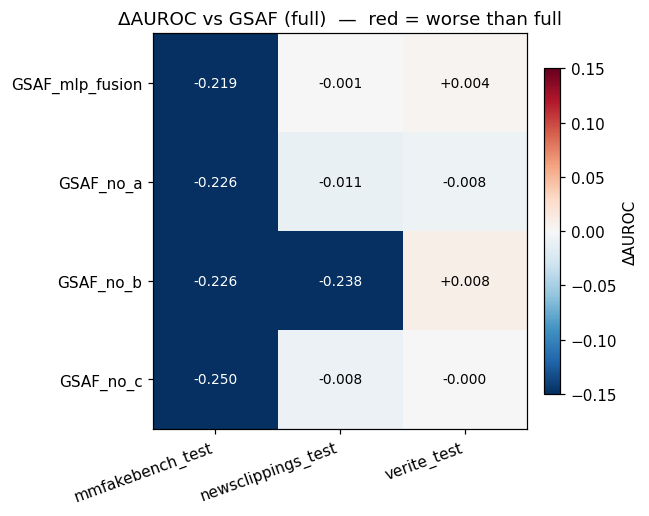

In [6]:
# Δ heatmap — skipped if no ablations stored
if deltas_df.empty:
    print("Skipping heatmap: no ablation variants. See note above.")
else:
    heat = deltas_df.pivot(index="model", columns="dataset", values="Δauroc")
    fig, ax = plt.subplots(figsize=(max(6, 1.3 * heat.shape[1]), 0.7 * len(heat) + 2))
    im = ax.imshow(heat.values, cmap="RdBu_r", vmin=-0.15, vmax=0.15, aspect="auto")
    ax.set_xticks(range(heat.shape[1]))
    ax.set_xticklabels(heat.columns, rotation=20, ha="right")
    ax.set_yticks(range(heat.shape[0]))
    ax.set_yticklabels(heat.index)
    for i in range(heat.shape[0]):
        for j in range(heat.shape[1]):
            v = heat.values[i, j]
            if not np.isnan(v):
                ax.text(j, i, f"{v:+.3f}", ha="center", va="center",
                        color="black" if abs(v) < 0.07 else "white", fontsize=9)
    ax.set_title("ΔAUROC vs GSAF (full)  —  red = worse than full")
    fig.colorbar(im, ax=ax, fraction=0.04, pad=0.04, label="ΔAUROC")
    plt.tight_layout()
    out = FIGURES / "ablations_delta_heatmap.png"
    plt.savefig(out, bbox_inches="tight", dpi=150)
    print("Saved:", out)
    plt.show()

## 6. Compare with `paper/tables/ablation_results.csv` (sanity check)

In [7]:
legacy = TABLES / "ablation_results.csv"
if legacy.exists():
    legacy_df = pd.read_csv(legacy)
    print("Existing ablation_results.csv preview:")
    print(legacy_df.head(20))
    print()
    print("Shapes — recomputed:", ablations_full.shape, "| legacy:", legacy_df.shape)
else:
    print("No legacy ablation_results.csv found.")


Existing ablation_results.csv preview:
   ablation               dataset    thr    acc     f1  f1_macro  auroc
0   default     newsclippings_val  0.482  69.15  68.47     69.13  76.01
1   default    newsclippings_test  0.482  69.01  68.34     69.00  76.32
2   default  mmfakebench_val_tune  0.486  82.00  86.84     79.18  89.92
3   default      mmfakebench_test  0.486  78.27  84.41     74.28  87.83
4   default           verite_test  0.482  62.54  76.34     43.21  48.13
5      no_a     newsclippings_val  0.482  67.51  68.39     67.49  74.29
6      no_a    newsclippings_test  0.482  67.30  68.20     67.28  75.23
7      no_a  mmfakebench_val_tune  0.486  62.00  71.30     57.54  61.19
8      no_a      mmfakebench_test  0.486  62.30  71.26     58.25  65.24
9      no_a           verite_test  0.482  64.34  77.92     42.60  47.37
10     no_b     newsclippings_val  0.482  50.58  65.94     37.97  51.82
11     no_b    newsclippings_test  0.482  49.97  65.46     37.37  52.49
12     no_b  mmfakebench_

---
**Done.** This notebook produces the ablation table the paper Section 5 will cite. The headline argument: GSAF beats MLP-fusion by ~22 points AUROC on MMFakeBench because the per-sample gate learns when to trust each stream.